In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")

### Load the Data


In [2]:
df = pd.read_csv(
    "superstore_orders.csv",
    engine="python",
    on_bad_lines="warn"
)

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [4]:
df.shape,  df['Customer ID'].nunique()

((10194, 21), 804)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales           10194 non-null 

In [7]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  object        
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null  object        
 15  Su

### Build the RFM Table

In [9]:
reference_date = df['Order Date'].max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer ID').agg(
                        Recency=('Order Date', lambda x: (reference_date - x.max()).days),
                        Frequency=('Order ID', 'nunique'),
                        Monetary=('Sales', 'sum')
                    ).reset_index()

In [10]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,AA-10315,185,5,5563.560
1,AA-10375,20,9,1056.390
2,AA-10480,260,4,1790.512
3,AA-10645,56,6,5086.935
4,AB-10015,416,3,886.156


In [11]:
rfm.shape

(804, 4)

### Scale the RFM Values

In [12]:
features = rfm[['Recency', 'Frequency', 'Monetary']]

scaled = StandardScaler().fit_transform(features)

### Run k-Means

In [13]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

In [20]:
rfm['Segment'] = kmeans.fit_predict(scaled)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Segment
0,AA-10315,185,5,5563.560,0
1,AA-10375,20,9,1056.390,3
2,AA-10480,260,4,1790.512,0
3,AA-10645,56,6,5086.935,3
4,AB-10015,416,3,886.156,1


### Describe each segment

In [15]:
summary = rfm.groupby('Segment')[['Recency','Frequency','Monetary']].mean()

summary['Customers'] = rfm.groupby('Segment').size()

summary.round(1)

,Recency,Frequency,Monetary,Customers
Segment,,,,
0,98.7,4.7,1615.7,340
1,546.1,3.8,1585.0,103
2,113.9,8.6,9449.9,67
3,70.6,8.7,3336.1,294


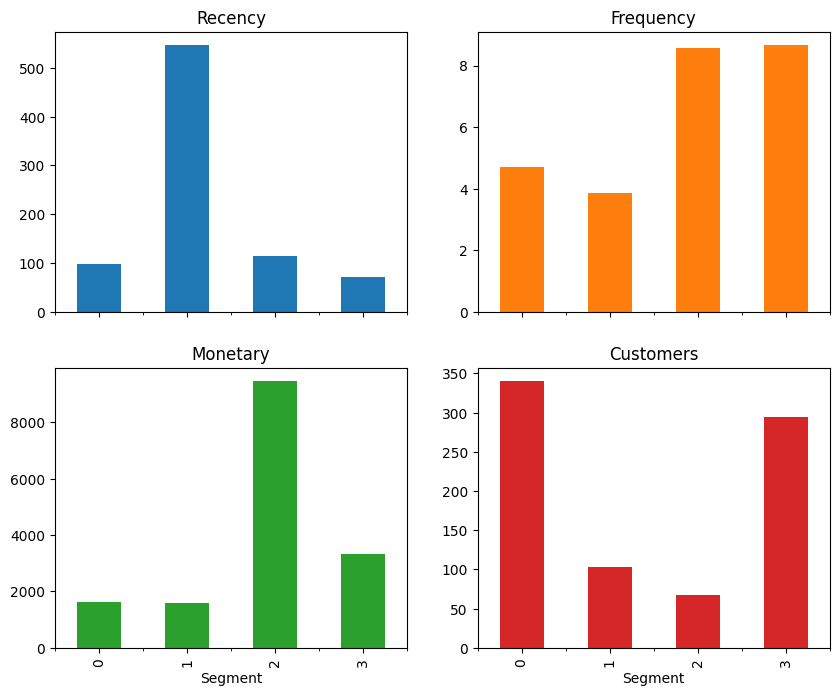

In [16]:
summary.plot(kind='bar', subplots=True, layout=(2,2), figsize=(10,8), legend=False)
plt.show()

### Visualize the Segments

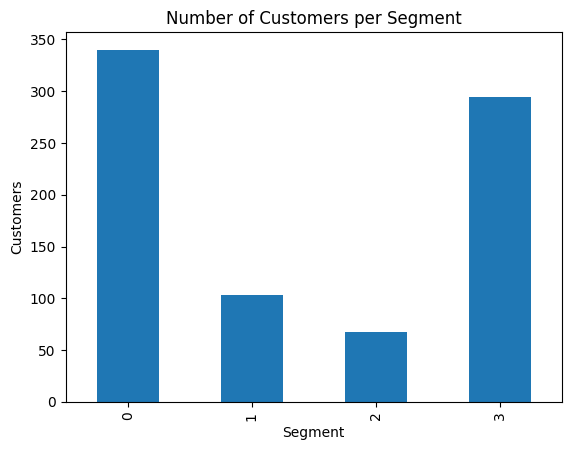

In [17]:
# how many customers in each segment
rfm['Segment'].value_counts().sort_index().plot(kind='bar')

plt.title('Number of Customers per Segment')
plt.xlabel('Segment')
plt.ylabel('Customers')
plt.show()


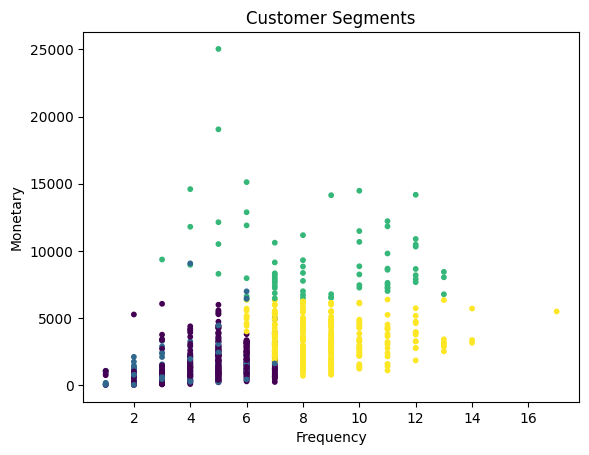

In [18]:
# see the segments spread out by Frequency and Monetary
plt.scatter(rfm['Frequency'], rfm['Monetary'],
            c=rfm['Segment'], cmap='viridis', s=10)

plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.title('Customer Segments')
plt.show()

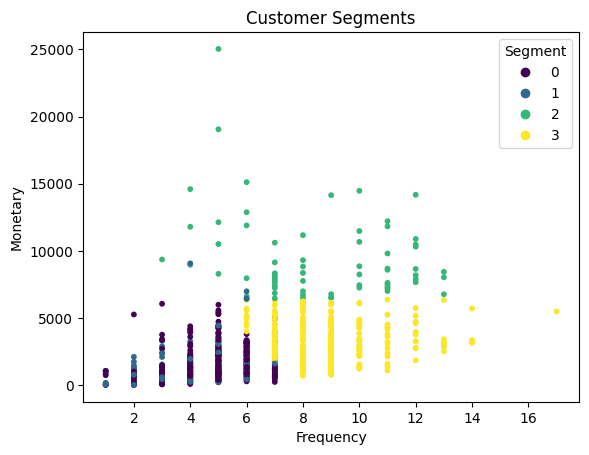

In [19]:
# see the segments spread out by Frequency and Monetary
scatter = plt.scatter(
    rfm['Frequency'],
    rfm['Monetary'],
    c=rfm['Segment'],
    cmap='viridis',
    s=10
)

plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.title('Customer Segments')

handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title='Segment')

plt.show()